# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [71]:
ROLL_NO = 1024160015          # <-- your full roll number
NAME = "Daksh Aggarwal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [72]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [73]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [74]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160015   Name: Daksh Aggarwal   Fingerprint: B38774E6   Tickets: 12

Ticket_ID                                                                 Ticket_Text
      T01               The email keeps asking for login. I have tried several times!
      T02                                          Dr. Rao's lab PC (No. 14) is down.
      T03                                                 My roll no. is 1023-03-021.
      T04                       I tried restarting the VPN on my laptop. Please help.
      T05                                 The lms crashes while opening. Please help.
      T06             Password is showing an error during the lab. Please resolve it.
      T07                                      Only 2 of 30 PCs boot after 3.5 hours.
      T08  I am unable to use the projector after resetting my password. Please help.
      T09 I reinstalled the VPN when I use mobile hotspot. I don't know what changed.
      T10                                             

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [75]:
rows = []
for i in df["Ticket_Text"]:
    temp = process_ticket(i)
    rows.append({
        "sentences": len(temp["sentences"]),
        "tokens": len(temp["tokens"]),
        "punctuation": len(temp["punct"]),
        "stopwords": len(temp["stops"]),
        "unique tokens": len(set(temp["tokens"])),
        "final tokens": len(temp["final"])
    })

df2 = pd.DataFrame(rows)
df2.loc["Total"] = df2.sum()
print(df2)

df2.iloc[2]


       sentences  tokens  punctuation  stopwords  unique tokens  final tokens
0              2      13            2          4             13             7
1              2      13            4          3             12             6
2              2       7            2          3              6             2
3              2      12            2          4             11             6
4              2       9            2          2              8             5
5              2      13            2          5             12             6
6              1      10            1          3             10             6
7              2      15            2          6             14             7
8              2      17            2          7             14             8
9              1       7            1          3              7             3
10             2      12            2          5             11             5
11             2      10            2          3              9 

,2
sentences,2
tokens,7
punctuation,2
stopwords,3
unique tokens,6
final tokens,2


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

The final tokens in our data that are not real words include "\'s" (from "Rao's") and "n't" (from "isn't"). These tokens originate during the tokenization stage, where nltk.word_tokenize splits standard English contractions into separate grammatical pieces. Because these contain alphabetical characters (so they are not categorized as punctuation) and are not present in NLTK's standard list of stopwords, they are preserved all the way through to the final tokens list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [76]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

string = ".".join(TEST_LINES)
regex = r'\b\w{6,}\b'

match = re.findall(regex, string)
print(match)

regex = r'\b\d+(?:[\.,]\d+)*\b'
match = re.findall(regex, string)
print(match)

regex = r'\b[A-Z][a-z]*\b'
match = re.findall(regex, string)
print(match)

regex = r'\b[aeiouAEIOU][a-zA-Z]*\b'
match = re.findall(regex, string)
print(match)

regex = r'\b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b'
match = re.sub(regex, '<EMAIL>', string)
print(match)

regex = r'\b(?:https?://|www\.)\S+\b'
match = re.sub(regex, '<URL>', string)
print(match)

regex = r'(?:\+\d{1,3}[- ]?)?\b\d{4,5}[- ]?\d{3}[- ]?\d{3,4}\b|(?:\+\d{1,3}[- ]?)?\b\d{5}[- ]?\d{5}\b'
match = re.sub(regex, '<PHONE>', string)
print(match)

['helpdesk', 'thapar', 'thapar', 'thapar', 'Version']
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250', '5.30']
['Mail', 'Call', 'Version', 'Rs', 'The']
['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it', 'or', 'is', 'of', 'art', 'isn', 'open', 'in', 'at']
Mail <EMAIL> or <EMAIL>; visit https://lms.thapar.edu/help or www.thapar.edu/it..Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250..The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit <URL> or <URL> +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250..The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it..Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250..

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

Out of 23 capitalized word occurrences extracted from the dataset, 15 of them are capitalized only because they appear at the start of a sentence. These words are: The, Please, My, Password, Only, Why, and . The remaining 8 occurrences ('I', 'Dr', 'Rao', 'No') are capitalized proper nouns, abbreviations, or pronouns.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [77]:
import nltk
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Using a single regex pattern, wrote using AI
regex = r'''(?x)
    \b[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}\b                       # Emails
    | \b(?:https?://|www\.)\S+\b                                              # URLs
    | (?:\+\d{1,3}[- ]?)?\b\d{4,5}[- ]?\d{3}[- ]?\d{3,4}\b                     # Phone Numbers (local/intl with spaces/dashes)
    | (?:\+\d{1,3}[- ]?)?\b\d{5}[- ]?\d{5}\b                                  # Phone Numbers (alternate format)
    | \b\d+(?:\.\d+)+\b                                                       # Decimals and versions (95.5, 2.0.1)
    | \b\w+(?:-\w+)+\b                                                        # Hyphenated words (Wi-Fi, state-of-the-art)
    | \b\w+(?:'\w+)?\b                                                        # Contractions and standard words
    | \S                                                                      # Remaining punctuation
'''

tokenizer = RegexpTokenizer(regex)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("For TEST_LINES")
for idx, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {idx}:")
    print("Original :", line)
    print("Custom   :", my_tokenize(line))
    print("Standard :", word_tokenize(line))

print("\n\nFor Tickets")
for idx, row in df.iterrows():
    text = row['Ticket_Text']
    print(f"\nTicket {row['Ticket_ID']}:")
    print("Original :", text)
    print("Custom   :", my_tokenize(text))
    print("Standard :", word_tokenize(text))

For TEST_LINES

Line 1:
Original : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom   : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
Standard : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2:
Original : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom   : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
Standard : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3:
Original : The state-of-the-art lab isn't

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

3 out of 12 tickets are tokenized differently.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [78]:
import string
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
import pandas as pd

unique_final_tokens = set()
for i in df["Ticket_Text"]:
    res = process_ticket(i)
    unique_final_tokens.update(res["final"])
unique_final_tokens = sorted(list(unique_final_tokens))

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer('ing$|ed$|s$', min=4) # using these three suffixes because they're quite common in the dataset
lemmatizer = WordNetLemmatizer()

pos_tagged_words = nltk.pos_tag(unique_final_tokens)

comparison_data = []
for word, pos in pos_tagged_words:
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp.stem(word)
    wn_pos = get_wordnet_pos(pos)
    lemmed = lemmatizer.lemmatize(word, pos=wn_pos)

    if len({p_stem, l_stem, r_stem, lemmed}) > 1:
        comparison_data.append({
            "Original Word": word,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "Lemmatizer": lemmed
        })

df_compare = pd.DataFrame(comparison_data)
pd.set_option('display.max_rows', None)
print(df_compare)

   Original Word     Porter Lancaster     Regexp Lemmatizer
0        another      anoth     anoth    another    another
1        changed      chang     chang      chang     change
2       computer     comput    comput   computer   computer
3        crashes      crash     crash     crashe      crash
4          error      error        er      error      error
5            lms         lm       lms        lms         lm
6         mobile      mobil      mobl     mobile     mobile
7        opening       open        op       open       open
8            pcs         pc       pcs        pcs         pc
9         please      pleas     pleas     please     please
10        portal     portal      port     portal     portal
11       printer    printer     print    printer    printer
12     projector  projector   project  projector  projector
13   reinstalled   reinstal  reinstal  reinstall  reinstall
14     resetting      reset     reset     resett      reset
15       resolve     resolv    resolv   

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

1. Over-stemming Example: Lancaster Stemmer over-stems "several" to "sev"

2. Under-stemming Example: RegexpStemmer under-stems "crashes" to "crash", leaving it as "crashe" because it only strips the trailing "s" rather than the complete suffix "es".

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus Stats
S1 (All Tokens): Tokens = 138, Unique Tokens = 80, TTR = 0.5797
S2 (No Punctuation): Tokens = 114, Unique Tokens = 75, TTR = 0.6579
S3 (Final Tokens): Tokens = 66, Unique Tokens = 51, TTR = 0.7727
S4 (S3 after Porter Stemmer): Tokens = 66, Unique Tokens = 49, TTR = 0.7424


Top 10 Words
S1 Top 10: [('.', 20), ('the', 9), ('i', 6), ('is', 5), ('please', 5), ('my', 3), ('help', 3), ('it', 3), ('tried', 2), ('lab', 2)]
S3 Top 10: [('please', 5), ('help', 3), ('tried', 2), ('lab', 2), ('vpn', 2), ('opening', 2), ('password', 2), ('resolve', 2), ('use', 2), ('projector', 2)]


 Top 5 Bigrams
S1 Top 5 Bigrams: [(('.', 'i'), 5), (('.', 'please'), 5), (('please', 'help'), 3), (('help', '.'), 3), (('no', '.'), 2)]
S3 Top 5 Bigrams: [(('please', 'help'), 3), (('please', 'resolve'), 2), (('email', 'keeps'), 1), (('keeps', 'asking'), 1), (('asking', 'login'), 1)]


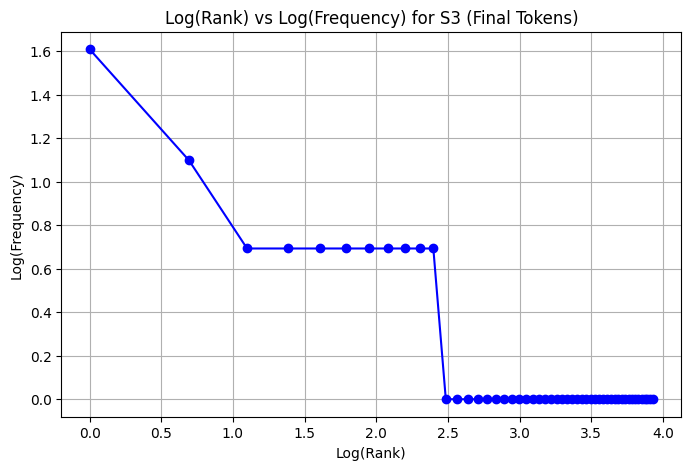

In [79]:
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

all_pipeline_results = [process_ticket(text) for text in df["Ticket_Text"]]

s1_tokens = []
for res in all_pipeline_results:
    s1_tokens.extend(res["tokens"])

s2_tokens = []
for res in all_pipeline_results:
    s2_tokens.extend([t for t in res["tokens"] if not is_punct(t)])

s3_tokens = []
for res in all_pipeline_results:
    s3_tokens.extend(res["final"])

porter = PorterStemmer()
s4_tokens = [porter.stem(t) for t in s3_tokens]

def compute_stats(tokens, name):
    num_tokens = len(tokens)
    num_unique = len(set(tokens))
    ttr = num_unique / num_tokens if num_tokens > 0 else 0
    print(f"{name}: Tokens = {num_tokens}, Unique Tokens = {num_unique}, TTR = {ttr:.4f}")
    return num_tokens, num_unique, ttr

print("Corpus Stats")
compute_stats(s1_tokens, "S1 (All Tokens)")
compute_stats(s2_tokens, "S2 (No Punctuation)")
compute_stats(s3_tokens, "S3 (Final Tokens)")
compute_stats(s4_tokens, "S4 (S3 after Porter Stemmer)")

print("\n\nTop 10 Words")
s1_counts = Counter(s1_tokens)
s3_counts = Counter(s3_tokens)
print("S1 Top 10:", s1_counts.most_common(10))
print("S3 Top 10:", s3_counts.most_common(10))

print("\n\n Top 5 Bigrams")
s1_bigrams = list(ngrams(s1_tokens, 2))
s3_bigrams = list(ngrams(s3_tokens, 2))
print("S1 Top 5 Bigrams:", Counter(s1_bigrams).most_common(5))
print("S3 Top 5 Bigrams:", Counter(s3_bigrams).most_common(5))

frequencies = sorted(s3_counts.values(), reverse=True)
ranks = list(range(1, len(frequencies) + 1))

log_ranks = [math.log(r) for r in ranks]
log_freqs = [math.log(f) for f in frequencies]

# plot log(rank) vs log(frequency) for S3
plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-', color='b')
plt.title("Log(Rank) vs Log(Frequency) for S3 (Final Tokens)")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

Type-Token Ratio (TTR) = Unique Tokens / Total Tokens.
It changes significantly through our preprocessing steps because each step alters either the total vocabulary size (types) or the total count of running words (tokens) in different proportions.

# Q6. Interpretation

Answer briefly:

(a) Why does TTR change from S1 to S4 in your dataset? <br>
*Answer: Answered above*

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.<br>
*Answer: Answered above*

(c) Give one example where stemming produces an undesirable result.<br>
*Answer: Answered above*

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.<br>
*Answer: For the word "crashes", POS-aware lemmatization correctly simplifies it to "crash", whereas the RegexpStemmer stems it incorrectly to "crashe".*